### 1.Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


### 2.Load Dataset

In [2]:
# Load Dataset
DATASET_PATH = Path("Unemployment in India.csv")
if not DATASET_PATH.exists():
    raise FileNotFoundError(f"Dataset not found: {DATASET_PATH.resolve()}")
df = pd.read_csv(DATASET_PATH)

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove extra spaces from text values
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()
print("Dataset Loaded Successfully!")
display(df.head())

Dataset Loaded Successfully!


C:\Users\Admin\AppData\Local\Temp\ipykernel_13900\477156347.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


### 3.Shape Inspection

In [3]:
print("Dataset Shape:", df.shape)

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

Dataset Shape: (768, 7)

Number of Rows: 768
Number of Columns: 7

Column Names:
['Region', 'Date', 'Frequency', 'Estimated Unemployment Rate (%)', 'Estimated Employed', 'Estimated Labour Participation Rate (%)', 'Area']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Region                                   740 non-null    str    
 1   Date                                     740 non-null    str    
 2   Frequency                                740 non-null    str    
 3   Estimated Unemployment Rate (%)          740 non-null    float64
 4   Estimated Employed                       740 non-null    float64
 5   Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                     740 non-null    str    
dtypes: float64(3), str(4)
memory 

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
count,740,740,740,740.000000,7.400000e+02,740.000000,740
unique,28,14,1,NaN,NaN,NaN,2
top,Andhra Pradesh,31-10-2019,Monthly,NaN,NaN,NaN,Urban
freq,28,55,740,NaN,NaN,NaN,381
mean,NaN,NaN,NaN,11.787946,7.204460e+06,42.630122,NaN
std,NaN,NaN,NaN,10.721298,8.087988e+06,8.111094,NaN
min,NaN,NaN,NaN,0.000000,4.942000e+04,13.330000,NaN
25%,NaN,NaN,NaN,4.657500,1.190404e+06,38.062500,NaN
50%,NaN,NaN,NaN,8.350000,4.744178e+06,41.160000,NaN
75%,NaN,NaN,NaN,15.887500,1.127549e+07,45.505000,NaN


### 4.Null Value Check

In [4]:
print("Missing Values:")
display(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Missing Values:


Region                                     28
Date                                       28
Frequency                                  28
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                       28
dtype: int64


Total Missing Values:
196

Duplicate Rows:
27


### 5.Data Cleaning & Type Conversion

In [5]:
# Required columns
required_columns = ["Region", "Date", "Estimated Unemployment Rate (%)", "Estimated Employed", "Estimated Labour Participation Rate (%)"]

# Check required columns
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise KeyError(f"Missing columns: {missing_columns}")

# Convert Date column
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True, errors="coerce")

# Convert numerical columns
numeric_columns = ["Estimated Unemployment Rate (%)", "Estimated Employed", "Estimated Labour Participation Rate (%)"]
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing required values
before_cleaning = len(df)
df.dropna(subset=required_columns, inplace=True)

# Remove duplicate records
df.drop_duplicates(inplace=True)

# Create Month column
df["Month"] = df["Date"].dt.to_period("M").dt.to_timestamp()

# Sort data
df.sort_values(by=["Date", "Region"], inplace=True)
df.reset_index(drop=True, inplace=True)

print("Data Cleaning Completed!")
print("Rows Before Cleaning:", before_cleaning)
print("Rows After Cleaning:", len(df))
print("Rows Removed:", before_cleaning - len(df))

print("\nRemaining Missing Values:")
display(df.isnull().sum())

print("\nCleaned Dataset:")
display(df.head())

Data Cleaning Completed!
Rows Before Cleaning: 768
Rows After Cleaning: 740
Rows Removed: 28

Remaining Missing Values:


C:\Users\Admin\AppData\Local\Temp\ipykernel_13900\3789261948.py:19: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(subset=required_columns, inplace=True)
C:\Users\Admin\AppData\Local\Temp\ipykernel_13900\3789261948.py:22: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)
C:\Users\Admin\AppData\Local\Temp\ipykernel_13900\3789261948.py:28: Pandas4Warning: The inplace keyword in DataFrame.sort_values is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.sort_values(by=["Date", "Region"], in

Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
Month                                      0
dtype: int64


Cleaned Dataset:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area,Month
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural,2019-05-01
1,Andhra Pradesh,2019-05-31,Monthly,6.09,4788661.0,37.45,Urban,2019-05-01
2,Assam,2019-05-31,Monthly,4.29,11749334.0,57.39,Rural,2019-05-01
3,Assam,2019-05-31,Monthly,7.87,1671707.0,44.92,Urban,2019-05-01
4,Bihar,2019-05-31,Monthly,9.27,24322330.0,39.75,Rural,2019-05-01


### 6.Region-wise Analysis

Region-wise Average Unemployment Rate:


,Average Unemployment Rate (%)
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


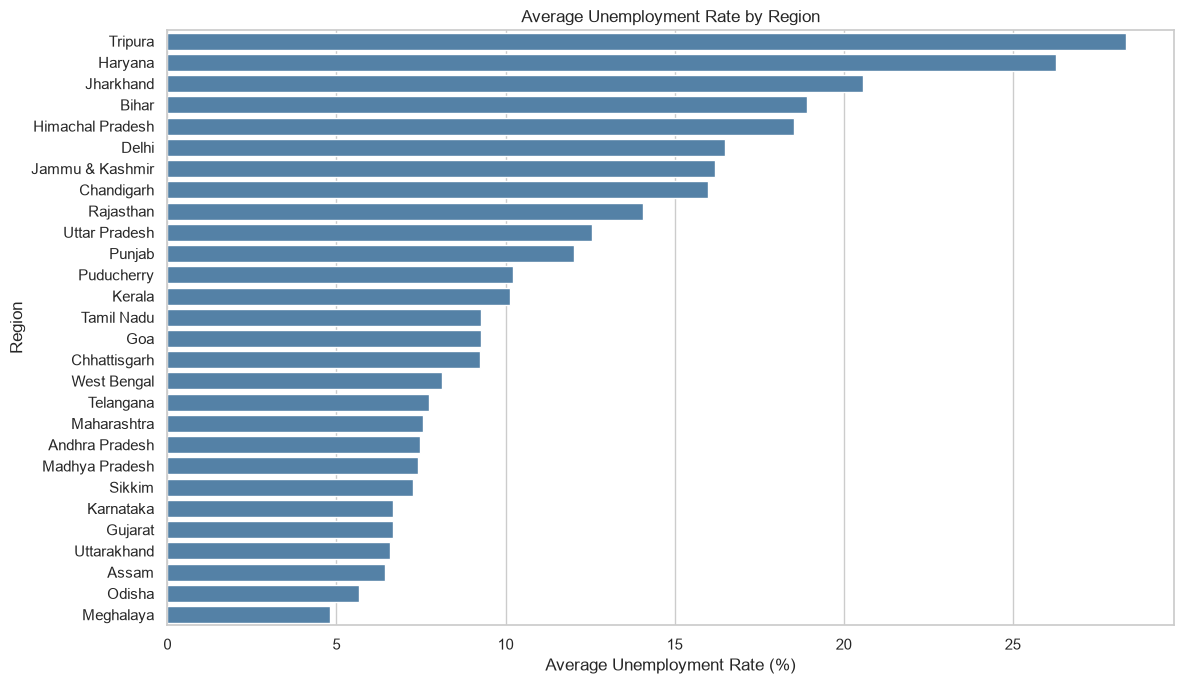

In [6]:
region_avg = (df.groupby("Region")["Estimated Unemployment Rate (%)"].mean().sort_values(ascending=False))
print("Region-wise Average Unemployment Rate:")
display(region_avg.to_frame(name="Average Unemployment Rate (%)"))
plt.figure(figsize=(12, 7))
sns.barplot(x=region_avg.values, y=region_avg.index, color="steelblue")

plt.title("Average Unemployment Rate by Region")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

### 7.Month-wise Trends

,Month,Estimated Unemployment Rate (%)
0,2019-05-01,8.874259
1,2019-06-01,9.303333
2,2019-07-01,9.033889
3,2019-08-01,9.637925
4,2019-09-01,9.051731
5,2019-10-01,9.900909
6,2019-11-01,9.868364
7,2019-12-01,9.497358
8,2020-01-01,9.950755
9,2020-02-01,9.964717


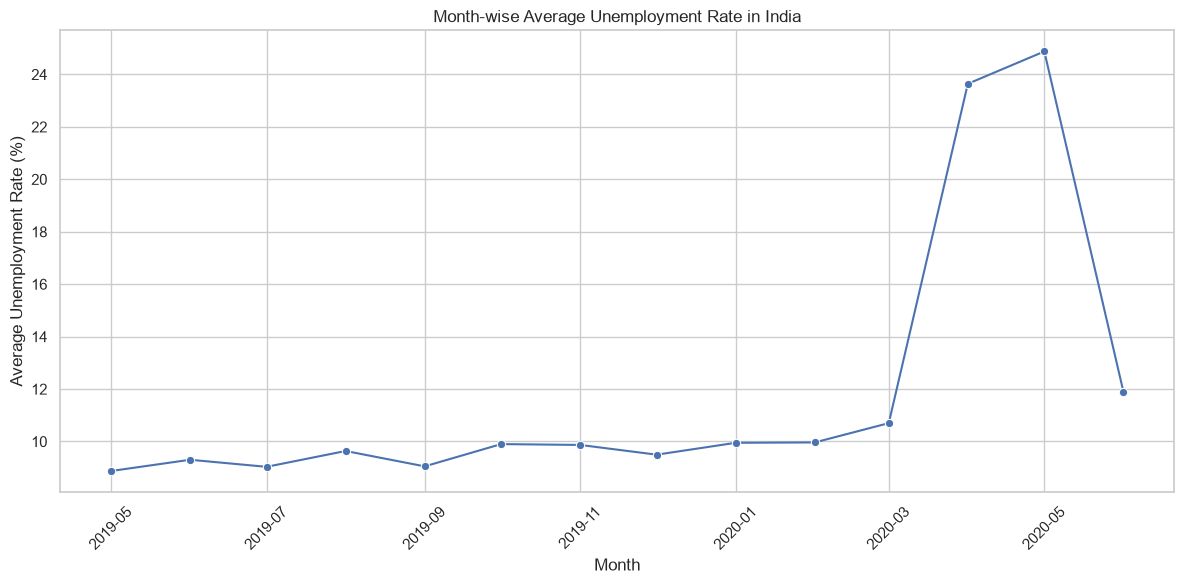

In [7]:
monthly_avg = (df.groupby("Month")["Estimated Unemployment Rate (%)"].mean().reset_index().sort_values("Month"))
display(monthly_avg)
plt.figure(figsize=(12, 6))
sns.lineplot(data=monthly_avg, x="Month", y="Estimated Unemployment Rate (%)", marker="o")

plt.title("Month-wise Average Unemployment Rate in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 8.Three Major States Time-Series Chart

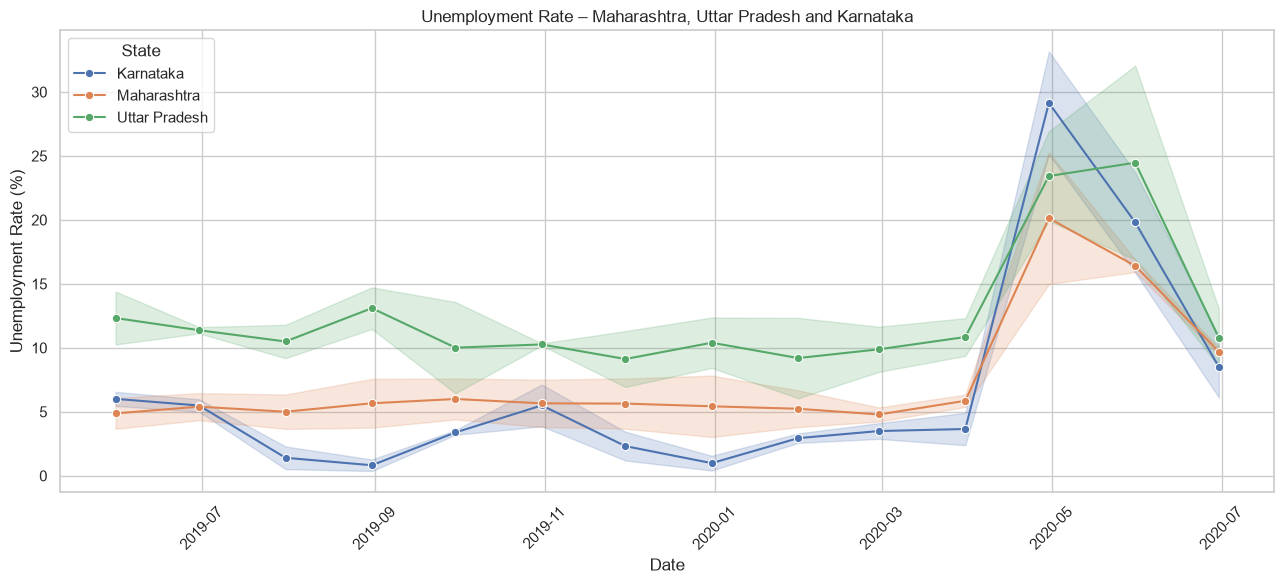

In [8]:
selected_states = ["Maharashtra", "Uttar Pradesh", "Karnataka"]
available_states = df["Region"].unique()
states_to_plot = [state for state in selected_states if state in available_states]

if len(states_to_plot) < 3:
    print("Warning: All three selected states are not available.")
    print("Available states:", states_to_plot)
else:
    state_data = df[df["Region"].isin(states_to_plot)]
    plt.figure(figsize=(13, 6))
    sns.lineplot(data=state_data, x="Date", y="Estimated Unemployment Rate (%)", hue="Region", marker="o")
    plt.title("Unemployment Rate – Maharashtra, " "Uttar Pradesh and Karnataka")

    plt.xlabel("Date")
    plt.ylabel("Unemployment Rate (%)")
    plt.xticks(rotation=45)
    plt.legend(title="State")

    plt.tight_layout()
    plt.show()

### 9.Top 10 States Bar Chart

Top 10 Regions with Highest Average Unemployment:


,Average Unemployment Rate (%)
Region,
Tripura,28.350357
Haryana,26.283214
Jharkhand,20.585000
Bihar,18.918214
Himachal Pradesh,18.540357
Delhi,16.495357
Jammu & Kashmir,16.188571
Chandigarh,15.991667
Rajasthan,14.058214


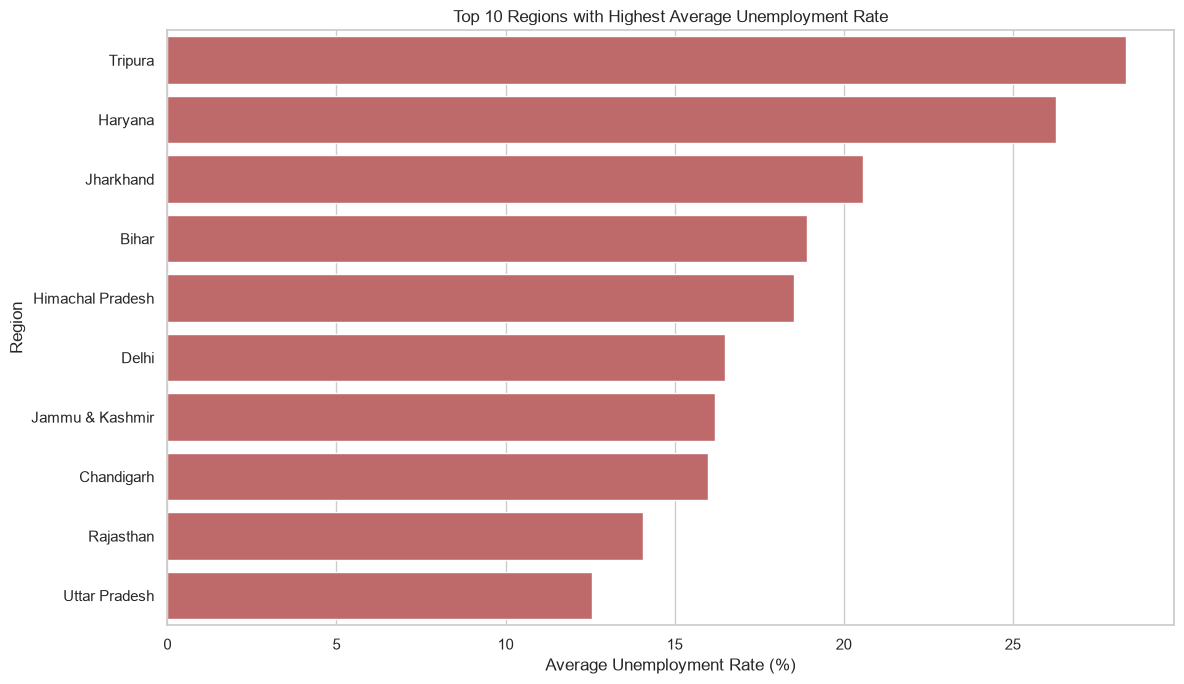

In [9]:
top_10_regions = region_avg.head(10)
print("Top 10 Regions with Highest Average Unemployment:")
display(top_10_regions.to_frame(name="Average Unemployment Rate (%)"))
plt.figure(figsize=(12, 7))
sns.barplot(x=top_10_regions.values, y=top_10_regions.index, color="indianred")

plt.title("Top 10 Regions with Highest Average Unemployment Rate")
plt.xlabel("Average Unemployment Rate (%)")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

### 10.Correlation Heatmap

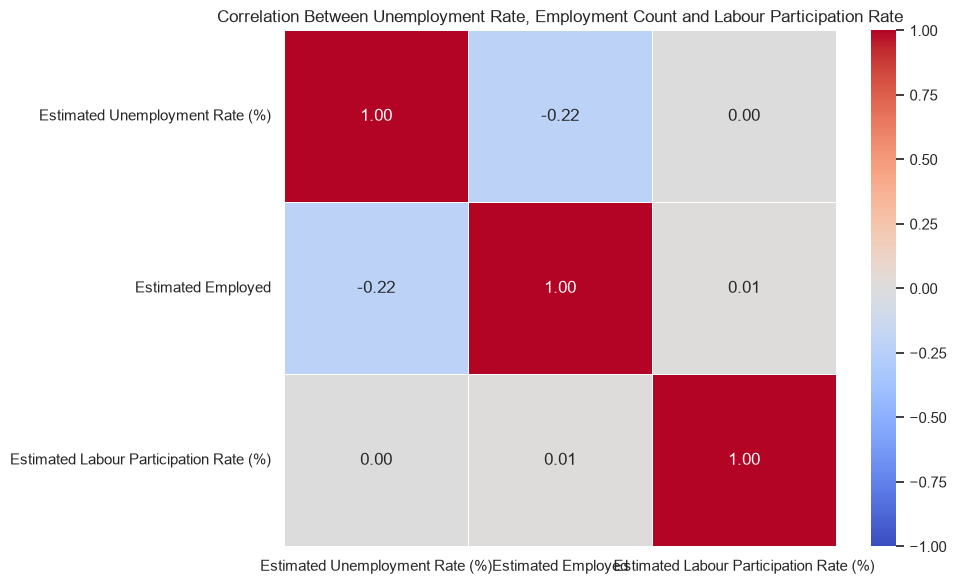

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
Estimated Unemployment Rate (%),1.000000,-0.222876,0.002558
Estimated Employed,-0.222876,1.000000,0.011300
Estimated Labour Participation Rate (%),0.002558,0.011300,1.000000


In [10]:
heatmap_columns = ["Estimated Unemployment Rate (%)", "Estimated Employed", "Estimated Labour Participation Rate (%)"]
correlation_matrix = df[heatmap_columns].corr()
plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation Between Unemployment Rate, " "Employment Count and Labour Participation Rate")
plt.tight_layout()
plt.show()
display(correlation_matrix)

### 11.Pre-COVID vs Post-COVID Analysis

,Period,Average Unemployment Rate (%),Number of Records
0,Pre-COVID,9.509534,536
1,Post-COVID,17.774363,204


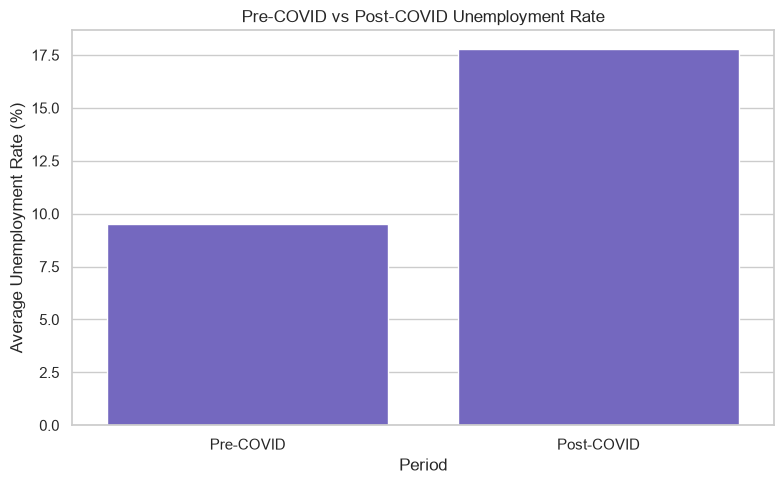

Difference: 8.26 percentage points


In [11]:
# COVID cutoff date
COVID_DATE = pd.Timestamp("2020-03-01")

# Split dataset
pre_covid = df[df["Date"] < COVID_DATE]
post_covid = df[df["Date"] >= COVID_DATE]

# Calculate average unemployment rates
pre_covid_mean = (pre_covid["Estimated Unemployment Rate (%)"].mean())
post_covid_mean = (post_covid["Estimated Unemployment Rate (%)"].mean())

# Comparison DataFrame
comparison = pd.DataFrame({"Period": ["Pre-COVID", "Post-COVID"], "Average Unemployment Rate (%)": [pre_covid_mean, post_covid_mean], "Number of Records": [len(pre_covid), len(post_covid)]})
display(comparison)

# Visualization
plt.figure(figsize=(8, 5))
sns.barplot(data=comparison, x="Period", y="Average Unemployment Rate (%)", color="slateblue")

plt.title("Pre-COVID vs Post-COVID Unemployment Rate")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

difference = post_covid_mean - pre_covid_mean
print("Difference:", round(difference, 2), "percentage points")

### Markdown Cell 1 – Data Cleaning Observation

### Markdown Cell 2 – Region-wise Observation

### Markdown Cell 3 – Month-wise Observation

### Markdown Cell 4 – Three-State Observation

### Markdown Cell 5 – Top 10 Observation

### Markdown Cell 6 – Heatmap Observation

### Markdown Cell 7 – COVID Observation

### 13.Final Findings

In [12]:
print("=" * 55)
print("FINAL FINDINGS – UNEMPLOYMENT ANALYSIS")
print("=" * 55)

print("\nDataset Information")
print("Total Records:", len(df))
print("Total Regions:", df["Region"].nunique())
print("Date Range:", df["Date"].min(), "to", df["Date"].max())
print("\nOverall Average Unemployment Rate:", round(df["Estimated Unemployment Rate (%)"].mean(), 2), "%")

print("\nHighest Average Unemployment Region:")
print(region_avg.idxmax(), "-", round(region_avg.max(), 2), "%")

print("\nLowest Average Unemployment Region:")
print(region_avg.idxmin(), "-", round(region_avg.min(), 2), "%")

print("\nPre-COVID Average:", round(pre_covid_mean, 2), "%")
print("Post-COVID Average:", round(post_covid_mean, 2), "%")

print("Difference:", round(difference, 2), "percentage points")
print("\nAnalysis Completed Successfully!")

FINAL FINDINGS – UNEMPLOYMENT ANALYSIS

Dataset Information
Total Records: 740
Total Regions: 28
Date Range: 2019-05-31 00:00:00 to 2020-06-30 00:00:00

Overall Average Unemployment Rate: 11.79 %

Highest Average Unemployment Region:
Tripura - 28.35 %

Lowest Average Unemployment Region:
Meghalaya - 4.8 %

Pre-COVID Average: 9.51 %
Post-COVID Average: 17.77 %
Difference: 8.26 percentage points

Analysis Completed Successfully!


### 14.Cleaned Dataset Export

In [13]:
output_file = "cleaned_unemployment_data.csv"
df.to_csv(output_file, index=False)

print("Cleaned Dataset Exported Successfully!")
print("File Name:", output_file)
print("Final Dataset Shape:", df.shape)

Cleaned Dataset Exported Successfully!
File Name: cleaned_unemployment_data.csv
Final Dataset Shape: (740, 8)
